# Supplementary Figure S6 — pathway coverage and carnitine localization

The single page contains A–B metastatic-status pathway context and C–E Wu-major Myeloid carnitine-node UMAPs. Coverage and UMAP localization are descriptive; inferred scores are not measured metabolite concentrations or flux.

In [1]:
from pathlib import Path
import hashlib, json
import matplotlib.pyplot as plt
from three_panel import PANEL_ORDER, load_data, make_panel, make_page
ROOT=Path.cwd(); DATA=load_data(ROOT/'data')
OUT=ROOT/'outputs'; PANELS=OUT/'panels'; PANELS.mkdir(parents=True,exist_ok=True)
print('Loaded', len(DATA), 'checksummed inputs')

Loaded 5 checksummed inputs


In [2]:
panel_manifest={'figure':'Figure S6','panel_order':list(PANEL_ORDER),'panels':{}}
for old in PANELS.glob('Figure_S6_[F-I].*'):
    old.unlink()
for label in PANEL_ORDER:
    fig=make_panel(label,DATA); panel_manifest['panels'][label]={}
    for ext in ('png','pdf','svg'):
        target=PANELS/f'Figure_S6_{label}.{ext}'
        fig.savefig(target,dpi=300,bbox_inches=None,pad_inches=0)
        payload=target.read_bytes(); panel_manifest['panels'][label][ext]={'path':str(target.relative_to(ROOT)),'bytes':len(payload),'sha256':hashlib.sha256(payload).hexdigest()}
    plt.close(fig)
(PANELS/'Figure_S6_panel_export_manifest.json').write_text(json.dumps(panel_manifest,indent=2)+'\n')
print('Exported A–E')

Exported A–E


In [3]:
from PIL import Image
fig=make_page(DATA)
fig.savefig(OUT/'Figure_S6.pdf',dpi=300,bbox_inches=None,pad_inches=0)
fig.savefig(OUT/'Figure_S6.png',dpi=300,bbox_inches=None,pad_inches=0)
fig.savefig(OUT/'Figure_S6.svg',dpi=300,bbox_inches=None,pad_inches=0)
plt.close(fig)
for old in OUT.glob('Figure_S6_page_*'):
    old.unlink()
with Image.open(OUT/'Figure_S6.png') as image:
    preview=image.copy(); preview.thumbnail((1600,1200)); preview.save(OUT/'Figure_S6_preview.png',optimize=True)
files={}
for target in [OUT/f'Figure_S6.{ext}' for ext in ('pdf','png','svg')]+[OUT/'Figure_S6_preview.png']:
    payload=target.read_bytes(); files[target.name]={'bytes':len(payload),'sha256':hashlib.sha256(payload).hexdigest()}
(OUT/'Figure_S6_export_manifest.json').write_text(json.dumps({'figure':'Figure S6','pages':1,'size':'A4 landscape','panel_order':list(PANEL_ORDER),'files':files},indent=2)+'\n')
print('Exported one A4 landscape page')

Exported one A4 landscape page


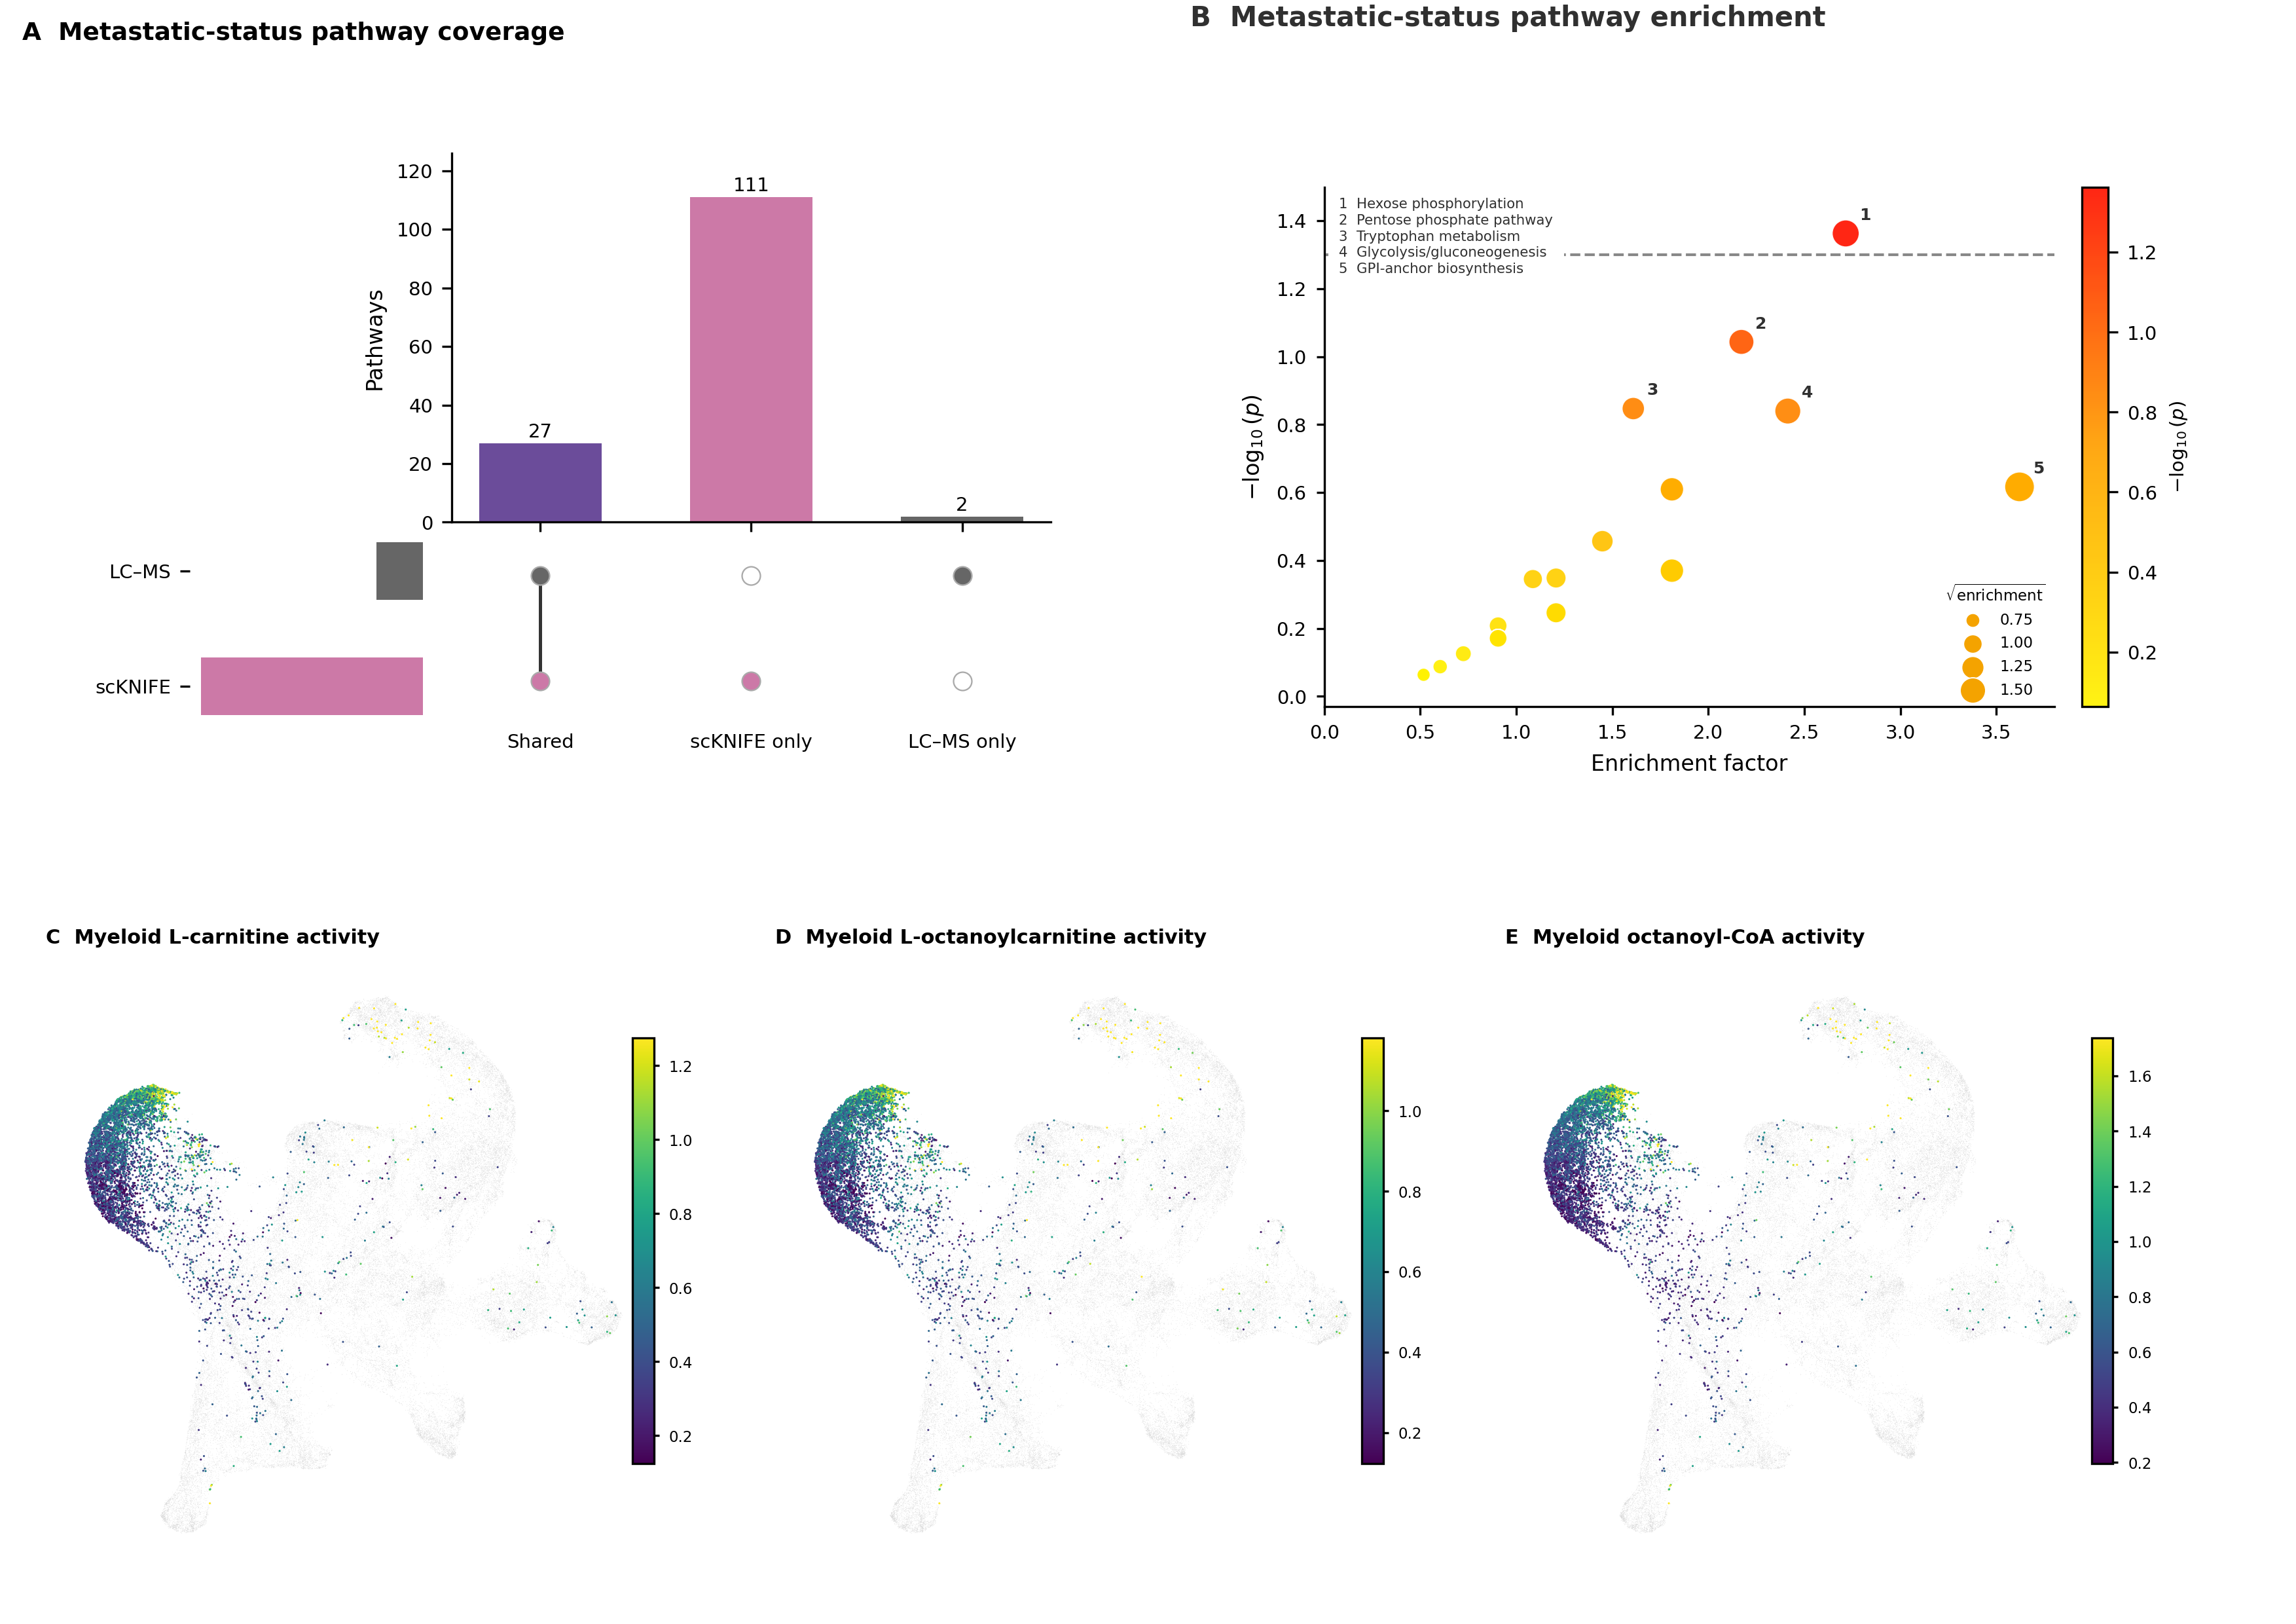

In [4]:
from IPython.display import Image, display
display(Image(filename='outputs/Figure_S6.png', width=1100))